# Sample analysis with `patientflow`

**Question:** at 12:00 on a given day, how many beds will be needed for emergency admissions before 20:00?

Demand comes from two sources:

1. patients **already in the ED** at 12:00 who will be admitted (predicted with a per-patient classifier, then aggregated);
2. patients **yet to arrive** who will arrive and be admitted within the window (predicted from historical arrival rates).

The pipeline lives in `analysis.py` at the project root; this notebook walks through it step by step. To regenerate the figures without Jupyter, run `python make_figures.py`.

In [ ]:
# In Patchwork the kernel runs in the browser: mount the project folder so
# `analysis`, `config.yaml` and `data/` are importable, and install patientflow.
# Locally (patientflow installed in .venv) this cell does nothing.
import sys

try:
    import patchwork
    in_patchwork = patchwork.connected()
except ImportError:
    in_patchwork = False

if in_patchwork:
    # micropip directly, not piplite: the tool's piplite has PyPI disabled.
    import micropip

    PROJECT = await patchwork.mount("automerge:4CmhvmpNoi5EJhtzmo6PjTHtbG4S", "/project")
    sys.path.insert(0, PROJECT)
    await micropip.install("patientflow==1.9.0")

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import analysis

## 1. Load the data

`ed_visits` holds one row per patient per *snapshot*: the state of each patient in the ED at 06:00, 09:30, 12:00, 15:30 and 22:00, with the label `is_admitted`.

`inpatient_arrivals` holds one row per admission, with its arrival time and specialty. Both are the `patientflow` synthetic datasets, copied into `data/`.

In [2]:
inputs = analysis.load_inputs()
ed_visits, inpatient_arrivals = inputs.ed_visits, inputs.inpatient_arrivals

print(f"{len(ed_visits):,} ED snapshots, {len(inpatient_arrivals):,} inpatient arrivals")
ed_visits.head()

79,713 ED snapshots, 12,636 inpatient arrivals


,snapshot_date,prediction_time,visit_number,elapsed_los,sex,age_group,arrival_method,current_location_type,total_locations_visited,num_obs,...,latest_lab_results_lac,latest_lab_results_na,latest_lab_results_pco2,latest_lab_results_ph,latest_lab_results_wcc,latest_lab_results_alb,latest_lab_results_htrt,final_sequence,is_admitted,specialty
snapshot_id,,,,,,,,,,,,,,,,,,,,,
324871,2031-03-01,"(6, 0)",1,20495,F,35-44,Ambulance,majors,2,22,...,NaN,138.0,NaN,7.0,NaN,NaN,NaN,[],False,NaN
325949,2031-03-01,"(15, 30)",2,27609,F,55-64,Walk-in,utc,3,26,...,NaN,NaN,NaN,7.0,NaN,49.0,NaN,[],False,NaN
326292,2031-03-01,"(12, 0)",3,12783,F,75-115,Walk-in,sdec,3,19,...,NaN,NaN,NaN,NaN,NaN,NaN,205.0,[paeds],False,NaN
326837,2031-03-01,"(15, 30)",4,20474,F,18-24,Walk-in,majors,6,48,...,2.5,NaN,NaN,NaN,NaN,NaN,NaN,[],False,NaN
326862,2031-03-01,"(15, 30)",5,9743,M,45-54,Walk-in,sdec,1,71,...,NaN,NaN,6.0,NaN,NaN,NaN,NaN,[],False,NaN


## 2. Quick exploration

In [3]:
ed_visits.groupby("prediction_time")["is_admitted"].agg(snapshots="count", admission_rate="mean").round(3)

,snapshots,admission_rate
prediction_time,,
"(6, 0)",8356,0.189
"(9, 30)",11282,0.133
"(12, 0)",18961,0.131
"(15, 30)",22430,0.173
"(22, 0)",18684,0.179


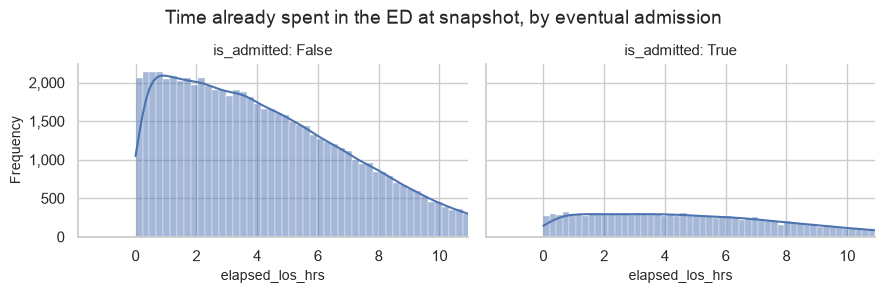

In [4]:
from patientflow.viz.data_distribution import plot_data_distribution

plot_data_distribution(
    df=ed_visits.assign(elapsed_los_hrs=ed_visits["elapsed_los"] / 3600),
    col_name="elapsed_los_hrs",
    grouping_var="is_admitted",
    grouping_var_name="whether patient admitted",
    plot_type="both",
    title="Time already spent in the ED at snapshot, by eventual admission",
    truncate_outliers=True,
    show=True,
)

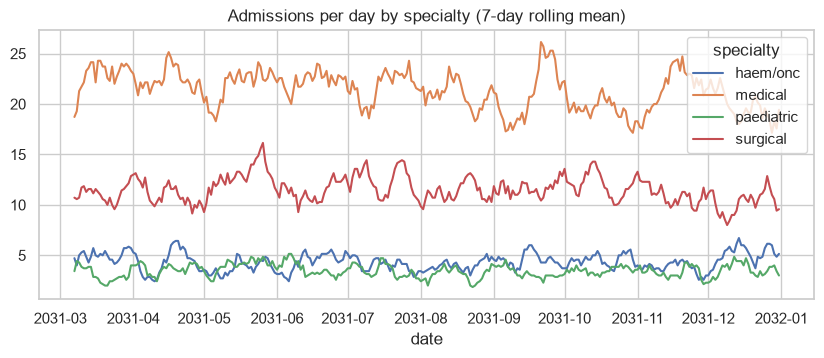

In [5]:
daily = inpatient_arrivals.assign(date=inpatient_arrivals.index.date)
daily.groupby(["date", "specialty"]).size().unstack(fill_value=0).rolling(7).mean().plot(
    figsize=(10, 3.5), title="Admissions per day by specialty (7-day rolling mean)"
)
plt.show()

## 3. Temporal split

Dates come from `config.yaml`: train from March 2031, calibrate in August, validate in September, test from October to December.

In [6]:
splits = analysis.split_visits(inputs)
{name: len(df) for name, df in vars(splits).items()}

{'train': 42024, 'calibration': 8420, 'validation': 7182, 'test': 22087}

## 4. Train one admission classifier per snapshot time

Each model is an XGBoost classifier trained on a balanced set and recalibrated (isotonic) on the calibration window. The features excluded from training and the ordinal mappings are defined in `analysis.py`.

`run_analysis` does the rest of the pipeline in one call:

- trains the models (`train_models`);
- for every test day and snapshot time, turns the per-patient admission probabilities into a distribution over *how many* patients in the ED will be admitted (`predict_bed_counts`);
- predicts the patients yet to arrive on the example day and combines both sources (`predict_yet_to_arrive`, `combine_demand`).

The figures below are the same ones `make_figures.py` saves.

In [7]:
results = analysis.run_analysis()
print(f"Example day: {results.example_day}, prediction time: {results.prediction_time}")
analysis.test_metrics(results.models)

Example day: 2031-10-11, prediction time: (12, 0)


,test_auc,test_logloss,test_auprc
admissions_0600,0.987,0.195,0.971
admissions_0930,0.995,0.074,0.978
admissions_1200,0.998,0.057,0.985
admissions_1530,0.998,0.056,0.989
admissions_2200,0.997,0.059,0.987


## 6. Patient-level evaluation (MADCAP)

MADCAP plots compare the cumulative predicted admissions against the cumulative observed admissions, with patients ordered by predicted probability. Closely tracking lines mean the probabilities are well calibrated.

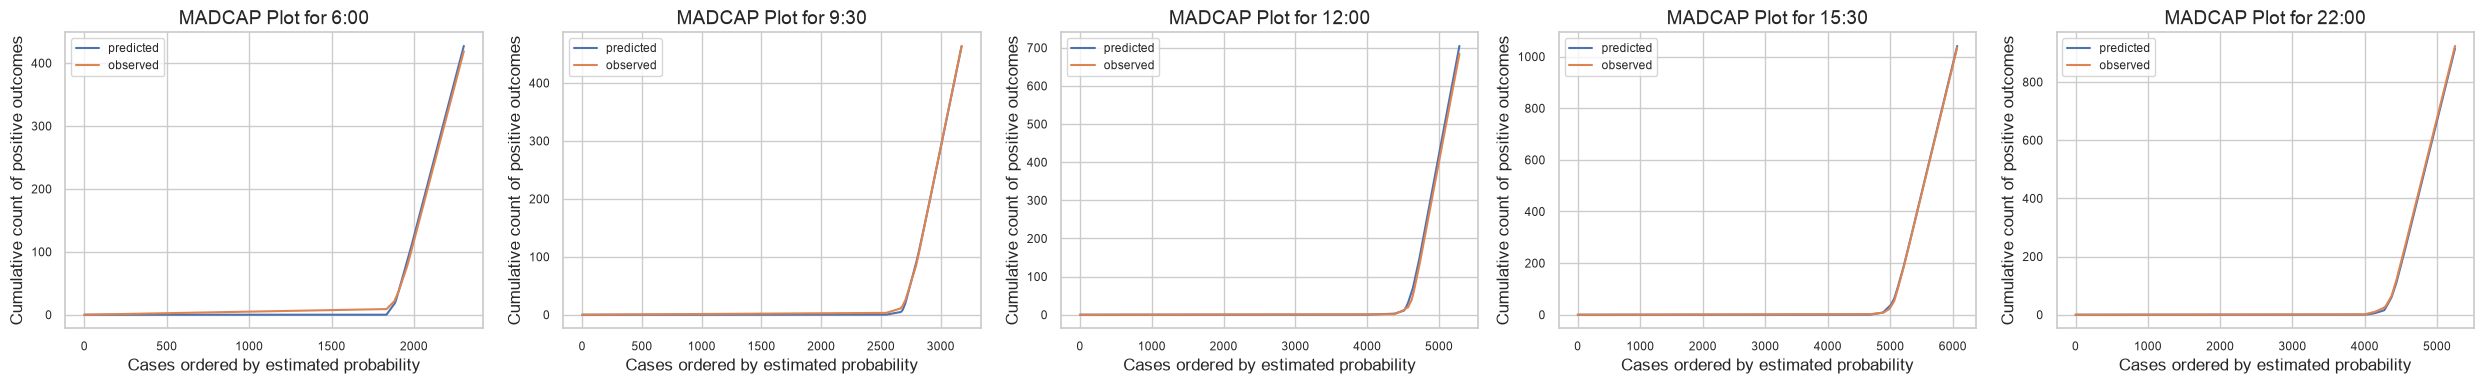

In [8]:
fig = analysis.madcap_figure(results)

## 7. Group-level evaluation (EPUDD)

Across all test days, where does the observed count fall within each day's predicted distribution? If the distributions are well calibrated, the observed points follow the diagonal.

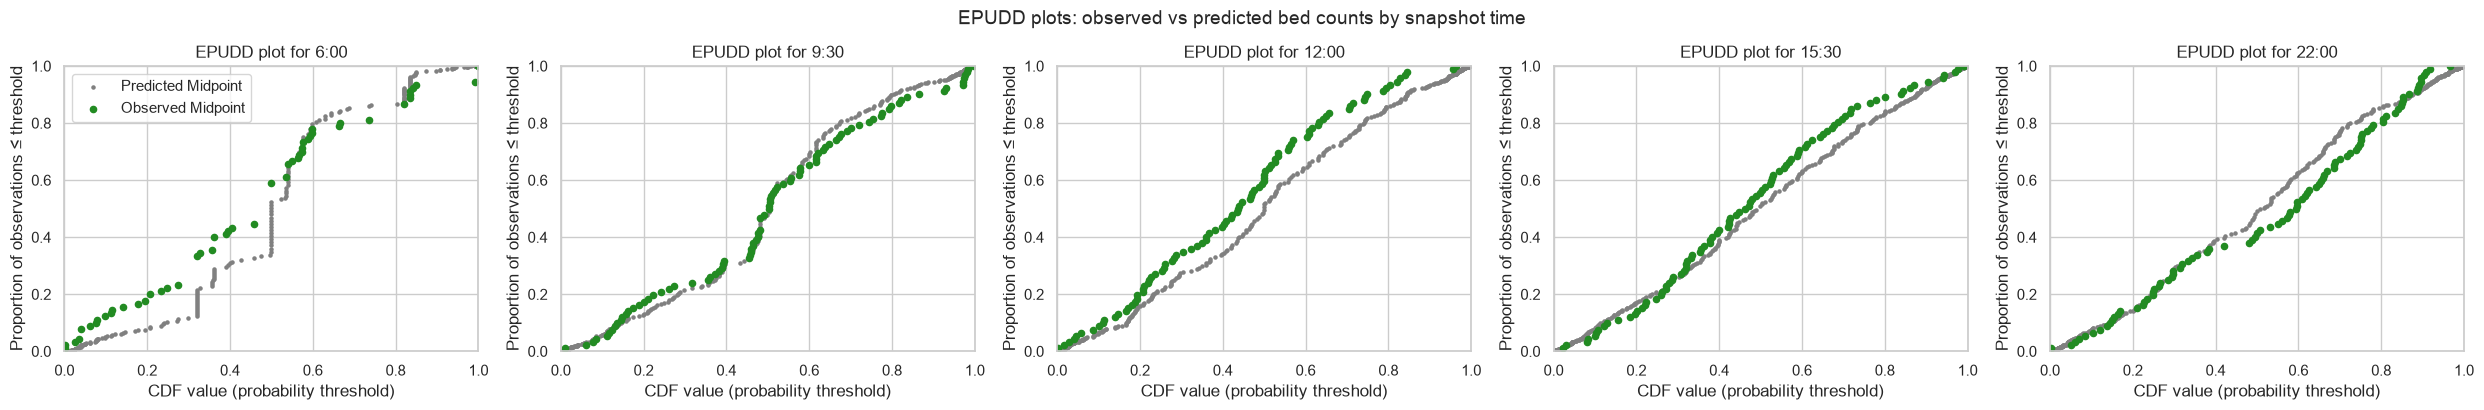

In [9]:
fig = analysis.epudd_figure(results)

## 8. The example day

First the patients already in the ED at 12:00, with the number actually admitted marked in red.

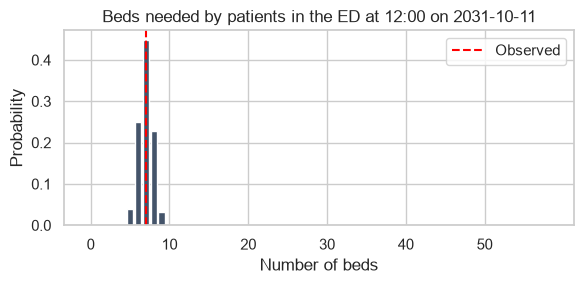

In [10]:
fig = analysis.in_ed_figure(results)

Then the patients who will arrive after 12:00 *and* be admitted before 20:00, assuming the ED meets the target in `config.yaml` (80% admitted within 4 hours, 99% within 12).

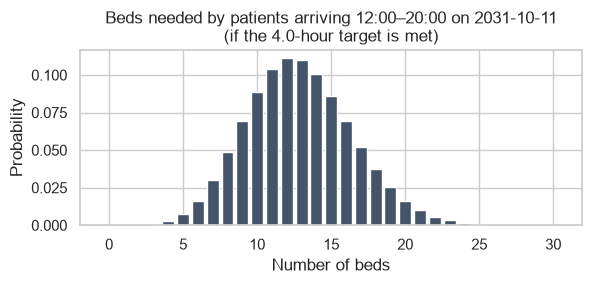

In [11]:
fig = analysis.yet_to_arrive_figure(results)

## 9. Total bed demand, 12:00–20:00

The two sources are treated as independent, so the distribution of their sum is the convolution of the two distributions.

expected beds                    19.8
median                           20.0
90% chance of needing at most    25.0
observed from patients in ED      7.0
dtype: float64

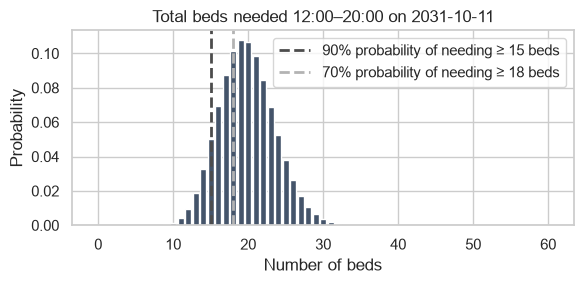

In [12]:
display(analysis.summarise_demand(results))
fig = analysis.total_demand_figure(results)